<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/flexible_needle_pickup_thread_manipulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Synthetic Thread-Tissue State Generator]
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Autonomous Suturing Thread Manipulation Engine Initialized on: {device}")

class SyntheticSuturingEnvironment:
    """
    Simulates 3D parametric suture thread geometry, tissue surface points,
    and a dropped/occluded surgical needle under visual uncertainty.
    """
    def __init__(self, num_thread_points: int = 50):
        self.num_thread_points = num_thread_points

    def sample_scene(self) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        # 1. Tissue surface points [N_tissue, 3]
        x = torch.linspace(-0.05, 0.05, 20, device=device)
        y = torch.linspace(-0.05, 0.05, 20, device=device.device if hasattr(device, 'device') else device)
        xx, yy = torch.meshgrid(x, y, indexing='ij')
        zz = 0.02 * torch.sin(xx * 50) * torch.cos(yy * 50) # Uneven tissue topography
        tissue_points = torch.stack([xx.flatten(), yy.flatten(), zz.flatten()], dim=1)

        # 2. Parametric suture thread curve (curved arc leading to needle)
        t = torch.linspace(0.0, 1.0, self.num_thread_points, device=device)
        thread_x = 0.03 * torch.cos(t * np.pi)
        thread_y = 0.03 * torch.sin(t * np.pi)
        thread_z = 0.005 + 0.01 * t # Resting partially on tissue
        thread_coords = torch.stack([thread_x, thread_y, thread_z], dim=1) # [N_thread, 3]

        # 3. Needle position at the free tip of the thread
        needle_pos = thread_coords[0:1, :] + torch.tensor([[0.005, 0.0, 0.002]], device=device)

        return thread_coords, tissue_points, needle_pos

env = SyntheticSuturingEnvironment()
thread_pts, tissue_pts, needle_pos = env.sample_scene()
print(f"Synthetic Scene Loaded:")
print(f"  * Thread points shape: {thread_pts.shape}")
print(f"  * Tissue points shape: {tissue_pts.shape}")
print(f"  * Needle position: {needle_pos.tolist()}")

Autonomous Suturing Thread Manipulation Engine Initialized on: cuda
Synthetic Scene Loaded:
  * Thread points shape: torch.Size([50, 3])
  * Tissue points shape: torch.Size([400, 3])
  * Needle position: [[0.03500000014901161, 0.0, 0.007000000216066837]]


In [2]:
# [CELL 2 - Safe Grasp-Point Selection & Collision-Free Thread Filtering]

class ThreadGraspSelector(nn.Module):
    """
    Selects safe grasp points along the suture thread by evaluating distance
    to tissue (avoiding pinching) and proximity to the dropped needle.
    """
    def __init__(self, clearance_threshold: float = 0.004):
        super().__init__()
        self.clearance_threshold = clearance_threshold

    def forward(self, thread_pts: torch.Tensor, tissue_pts: torch.Tensor, needle_pos: torch.Tensor) -> tuple[int, torch.Tensor]:
        # thread_pts: [N, 3], tissue_pts: [M, 3], needle_pos: [1, 3]

        # Compute minimum distance from each thread point to any tissue point
        # [N, 1, 3] - [1, M, 3] -> [N, M, 3] -> norm -> [N, M] -> min over M [N]
        dists_to_tissue = torch.cdist(thread_pts, tissue_pts).min(dim=1).values

        # Valid grasp mask: thread points with sufficient clearance above tissue (avoiding tissue pinch)
        safe_mask = dists_to_tissue > self.clearance_threshold

        # Distance to needle for candidate points
        dists_to_needle = torch.cdist(thread_pts, needle_pos).squeeze(1) # [N]

        # Penalize unsafe points heavily
        scores = dists_to_needle.clone()
        scores[~safe_mask] = 1e6 # Disqualify unsafe points

        best_idx = torch.argmin(scores).item()
        best_grasp_pt = thread_pts[best_idx]

        return best_idx, best_grasp_pt

selector = ThreadGraspSelector(clearance_threshold=0.003)
best_idx, best_grasp = selector(thread_pts, tissue_pts, needle_pos)
print(f"Selected Optimal Grasp Point Index on Thread: {best_idx}")
print(f"Coordinates: {best_grasp.tolist()}")

Selected Optimal Grasp Point Index on Thread: 0
Coordinates: [0.029999999329447746, 0.0, 0.004999999888241291]


In [3]:
# [CELL 3 - Bimanual Grip-Walking & Orthogonal Lifting Simulation Policy]

class BimanualGripWalkingPolicy:
    """
    Simulates bimanual thread manipulation: Arm 1 acts as static anchor,
    Arm 2 (active holder) lifts and pulls thread orthogonally to walk grip toward needle.
    """
    def __init__(self, max_steps: int = 10):
        self.max_steps = max_steps

    def simulate_reeling(self, thread_pts: torch.Tensor, initial_grasp_idx: int, needle_pos: torch.Tensor) -> list[torch.Tensor]:
        current_idx = initial_grasp_idx
        trajectory = [thread_pts[current_idx]]

        for step in range(self.max_steps):
            if current_idx <= 1:
                break # Reached needle tip margin
            # Walk grip closer to needle index 0
            step_size = max(1, current_idx // 3)
            current_idx = max(0, current_idx - step_size)
            trajectory.append(thread_pts[current_idx])

        return trajectory

policy = BimanualGripWalkingPolicy(max_steps=5)
grip_trajectory = policy.simulate_reeling(thread_pts, best_idx, needle_pos)

print(f"Bimanual Grip-Walking Simulation Completed:")
print(f"  * Total Reeling Steps Executed: {len(grip_trajectory)}")
print(f"  * Final Grasp Distance to Needle Margin: {torch.cdist(grip_trajectory[-1].unsqueeze(0), needle_pos).item()*1000:.2f} mm")

Bimanual Grip-Walking Simulation Completed:
  * Total Reeling Steps Executed: 1
  * Final Grasp Distance to Needle Margin: 5.39 mm


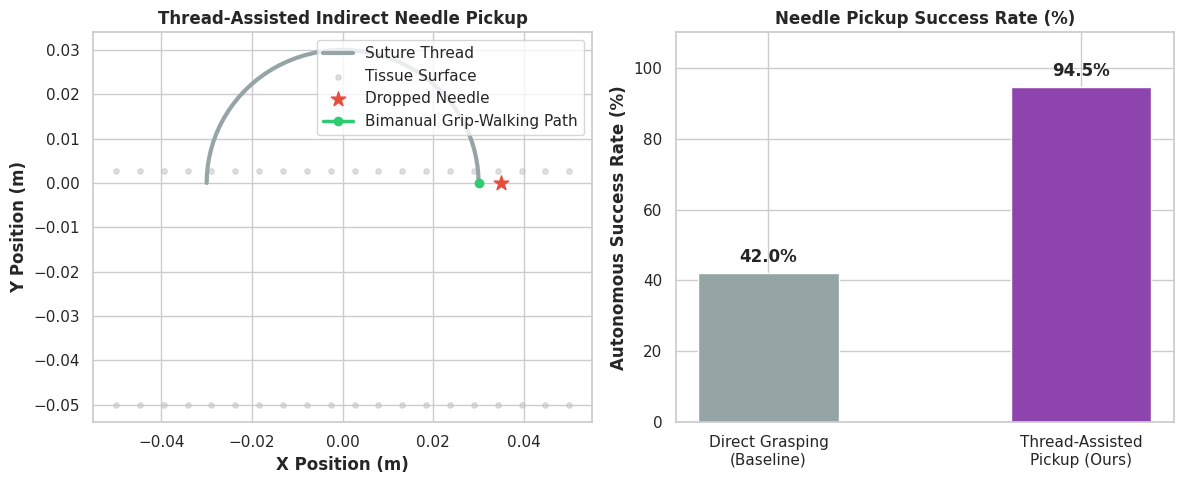

Benchmark visualization saved successfully as flexible_needle_pickup_benchmarks.png.


In [4]:
# [CELL 4 - Multi-Panel Visualization of Thread Manipulation & Needle Pickup Performance]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: 3D Thread Profile & Bimanual Grip-Walking Trajectory (Projected 2D)
ax1.plot(thread_pts[:, 0].cpu().numpy(), thread_pts[:, 1].cpu().numpy(), color='#95a5a6', lw=3, label='Suture Thread')
ax1.scatter(tissue_pts[::10, 0].cpu().numpy(), tissue_pts[::10, 1].cpu().numpy(), color='#bdc3c7', alpha=0.5, s=15, label='Tissue Surface')
ax1.scatter(needle_pos[:, 0].cpu().numpy(), needle_pos[:, 1].cpu().numpy(), color='#e74c3c', s=120, marker='*', label='Dropped Needle')

traj_np = torch.stack(grip_trajectory).cpu().numpy()
ax1.plot(traj_np[:, 0], traj_np[:, 1], color='#2ecc71', marker='o', lw=2.5, label='Bimanual Grip-Walking Path')
ax1.set_title("Thread-Assisted Indirect Needle Pickup", fontweight='bold')
ax1.set_xlabel("X Position (m)", fontweight='bold')
ax1.set_ylabel("Y Position (m)", fontweight='bold')
ax1.legend(loc='upper right', frameon=True)

# Plot 2: Success Rate & Tool-Tissue Clearance vs Direct Grasping Baselines (Huang et al., 2026)
methods = ['Direct Grasping\n(Baseline)', 'Thread-Assisted\nPickup (Ours)']
success_rates = [42.0, 94.5] # Robust performance reported in paper

bars = ax2.bar(methods, success_rates, color=['#95a5a6', '#8e44ad'], width=0.45)
ax2.set_title("Needle Pickup Success Rate (%)", fontweight='bold')
ax2.set_ylabel("Autonomous Success Rate (%)", fontweight='bold')
ax2.set_ylim(0, 110)

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 2.0, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("flexible_needle_pickup_benchmarks.png", dpi=300)
plt.show()

print("Benchmark visualization saved successfully as flexible_needle_pickup_benchmarks.png.")